[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridVQNN_IoTIntrusionDetection_Shrivastava2026.ipynb)

# Hybrid quantum-classical variational neural network (HQCVNN) for intrusion detection: Shrivastava et al. (2026) step by step

**Paper.** Aayush Shrivastava, Lalit Kumar, Nikhat Raza Khan, Amit Bindal, Ashish Singhal and Sameeksha Verma,
*Quantum-Enhanced Hybrid Variational Neural Network for IoT Intrusion Detection*,
2026 2nd International Conference on Big Data & Machine Learning (ICBDML), IEEE, 2026.
DOI [10.1109/ICBDML68582.2026.11544431](https://doi.org/10.1109/ICBDML68582.2026.11544431). The paper publishes no code.

**What this notebook does.** It re-implements the model of Fig. 1 and Fig. 2 of the paper from its description and tests the
claims of its Tables I-III and Figs. 3-5:

1. downloads the **CIC-IDS-2017** flow records (the one dataset the paper actually evaluates on) and builds a class-balanced
   sample of about 10,000 flows with the paper's **four** hand-picked features (Flow Duration, Flow Bytes/s, Total Forward
   Packets, Packet Length Mean) and a stratified 70/30 split;
2. encodes the four features as four `Ry` angles, applies **3 variational layers** (`Ry`, `Rz`, ring of CNOTs) on **4 qubits**,
   measures the Pauli-Z expectation of every qubit and feeds the four numbers to a small dense network with a softmax output;
3. trains it end to end with Adam, batch size 32, cross-entropy loss and the parameter-shift rule (here: exact autograd,
   proven to be identical to the Qiskit parameter-shift gradient in the circuit section);
4. trains the paper's two baselines (an SVM and a roughly 10,000-parameter ANN) **and** two extra controls
   (a random forest, and the *same dense head without the quantum layer*) on exactly the same inputs;
5. prints the paper's numbers next to the notebook's and gives a verdict per claim, followed by a critical reading.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` is a class demo (3,000 flows, 10 epochs, one seed; about 3 minutes plus the one-time data
download and cleaning); `FAST_MODE = False` uses the paper's 100 epochs, 10,000 flows and 3 seeds (about an hour on a
loaded laptop CPU). The published copy of this notebook holds the outputs of the mode set in the configuration cell.

**What you get at the end.** The dataset visualised with real labels, the executed circuit drawn and checked against
Qiskit, a table with accuracy / precision / recall / F1 / AUC / parameter count / time for every model (mean and standard
deviation over seeds), the paper's Figs. 3-5 re-drawn, and an honest comparison with the paper's numbers.

## The paper in one page

**Problem.** Classify a network flow as *normal* or *attack*. The title and abstract talk about "IoT intrusion detection", but
the only dataset the experiments use is **CIC-IDS-2017** (an enterprise-network capture, not an IoT capture).

**Method (Fig. 1).** Traffic data -> preprocessing and feature selection (min-max normalisation, label encoding, top-*k*
features so that *k* equals the number of qubits) -> *quantum processing layer*: angle (`Ry`) encoding followed by a
variational circuit of parameterised rotations and CNOT entanglers -> *measurement layer*: Pauli-Z expectation values ->
*classical classification layer*: fully connected network with softmax -> cross-entropy loss; quantum parameters are updated
with the parameter-shift rule (Eq. 10), classical weights with Adam.

**Configuration (Fig. 2).** 70 % training / 30 % testing, stratified; **4 qubits, 3 variational layers**, Adam,
**100 epochs, batch size 32**; Python with Qiskit (circuit simulation) and PyTorch (dense layers); metrics: accuracy,
precision, recall, F1, confusion matrix, ROC curve.

**Data.** CIC-IDS-2017 (Kaggle copy `chethuhn/network-intrusion-dataset`), 80+ flow features, DDoS / DoS Hulk / brute force /
botnet / infiltration / port-scan attacks. Four features are kept: Flow Duration, Flow Bytes/s, Total Fwd Packets,
Packet Length Mean.

**Claims to test.**

| Source | Claim |
|---|---|
| Table I | HQCVNN: accuracy 94.1 %, precision 0.93, recall 0.92, F1 0.92, AUC 0.96, about 2,000 trainable parameters |
| Table I | ANN: 91.2 %, 0.89 / 0.90 / 0.89, AUC 0.92, about 10,000 parameters |
| Table I | SVM: 88.4 %, 0.86 / 0.85 / 0.85, AUC 0.89 |
| Table II | confusion matrix of the HQCVNN on 3,000 test flows: TN 1450, FP 70, FN 85, TP 1395 |
| Table III, Fig. 4 | AUC ordering HQCVNN (0.96) > ANN (0.92) > SVM (0.89) |
| Fig. 3 | accuracy ordering HQCVNN > ANN > SVM |
| Fig. 5 | training and validation loss fall together without much overfitting |
| Conclusion | the quantum-enhanced feature map improves non-linear separability; training is slightly slower than classical |

The test set implied by Table II has 1,520 normal + 1,480 attack flows = 3,000 flows, i.e. 30 % of **about 10,000** flows.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | CIC-IDS-2017 (Kaggle copy) | CIC-IDS-2017, all 8 daily CSV files, Hugging Face mirror `c01dsnap/CIC-IDS2017` (same CICFlowMeter files) |
| Sample size | not stated; Table II implies 3,000 test flows | **10,000** flows (5,000 normal + 5,000 attack, drawn at random from the cleaned pool) in the full run, 3,000 in `FAST_MODE` |
| Attack mix | "DDoS, DoS Hulk, brute force, botnet, infiltration, port scan" | attack flows drawn uniformly from the cleaned pool of all attack rows, so the mix follows the natural frequencies (DoS Hulk and DDoS dominate) |
| Split | 70 / 30 stratified | 70 / 30 stratified; **10 % of the training part is held out as a validation set for the loss curve only** (CHOICE) |
| Features | Flow Duration, Flow Bytes/s, Total Fwd Packets, Packet Length Mean | the same four columns |
| Normalisation | min-max | **signed log1p then min-max to [0, pi]**, fitted on the training part only (CHOICE: the raw features span 8 orders of magnitude; the literal min-max version is run as an ablation) |
| Encoding | angle embedding with `Ry` | `Ry(x_i)` on qubit *i*, one feature per qubit, angles in [0, pi] |
| Variational block | 3 layers of parameterised rotations + CNOT entanglers | each layer: `Ry(theta)` and `Rz(phi)` on every qubit, then a ring of CNOTs (0-1, 1-2, 2-3, 3-0) (CHOICE: gate order and ring topology are not stated) |
| Measurement | Pauli-Z expectation values | `<Z_i>` of every qubit -> 4 numbers |
| Classical head | "fully connected network with softmax" | `4 -> 48 -> 32 -> 2` with ReLU, softmax inside the cross-entropy loss (CHOICE: sized so that the whole model has about 2,000 parameters as in Table I) |
| ANN baseline | about 10,000 parameters | `4 -> 96 -> 72 -> 32 -> 2` with ReLU = 9,866 parameters, same optimiser, epochs and batch size (CHOICE) |
| SVM baseline | kernel not stated | `SVC(kernel="rbf", C=1, gamma="scale")` (CHOICE) |
| Optimiser | Adam, 100 epochs, batch 32, learning rate not stated | Adam, 100 epochs, batch 32, learning rate 0.01 (0.02 in `FAST_MODE`) (CHOICE) |
| Gradients | parameter-shift rule | exact simulation with automatic differentiation; the notebook proves that this equals the parameter-shift gradient of the Qiskit circuit |
| Simulator | Qiskit + PyTorch | Qiskit builds, draws and checks the circuit; the training loop uses an exact 4-qubit state-vector simulator written in PyTorch (about 100x faster than calling the Qiskit primitives for every sample; equivalence asserted) |
| Seeds | not stated | `SEED = 42`, several seeds in the full run (each seed re-draws the sample, the split and the initial weights) |
| AUC, precision, recall, F1 | averaging not stated | attack = positive class (binary) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util, subprocess, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install",
                    "qiskit==2.5.2", "qiskit-machine-learning==0.9.1", "pylatexenc"], check=True)
    print("Qiskit installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning already present; skipping pip install.")

qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False          # True: 3,000 flows, 10 epochs, 1 seed (class demo). False: paper budgets (10,000 flows, 100 epochs, 3 seeds).
SEED      = 42            # CHOICE: the paper does not give a seed

N_QUBITS   = 4            # paper: 4 qubits (one per selected feature)
N_LAYERS   = 3            # paper: 3 variational layers
BATCH_SIZE = 32           # paper
TEST_SIZE  = 0.30         # paper: 70 / 30 stratified split
VAL_FRAC   = 0.10         # CHOICE: share of the training part held out to draw the validation-loss curve (Fig. 5)

if FAST_MODE:
    N_TOTAL, EPOCHS, N_SEEDS, LR = 3_000, 10, 1, 0.02
else:
    N_TOTAL, EPOCHS, N_SEEDS, LR = 10_000, 100, 3, 0.01   # paper: 100 epochs; Table II implies a 3,000-flow test set

FEATURES = ["Flow Duration", "Flow Bytes/s", "Total Fwd Packets", "Packet Length Mean"]   # the paper's four features
DATA_DIR = "cicids2017_data"       # CSV files are cached here; put your own copies here to skip the download
IBM_TOKEN = ""                     # not used: the paper never runs on hardware, everything is simulated
print(f"FAST_MODE={FAST_MODE}: N_TOTAL={N_TOTAL}, EPOCHS={EPOCHS}, N_SEEDS={N_SEEDS}, LR={LR}")

FAST_MODE=False: N_TOTAL=10000, EPOCHS=100, N_SEEDS=3, LR=0.01


In [3]:
import os, re, time, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch, torch.nn as nn
import sklearn, qiskit, qiskit_machine_learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, FunctionTransformer, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector

warnings.filterwarnings("ignore")
algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)      # CHOICE: the models are tiny (batch 32); one thread is fastest and keeps a shared CPU usable
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})

# Hugging Face token: only needed for gated datasets. CIC-IDS-2017 on the mirror below is public, so None is fine.
# If you use a gated dataset, add your own token in Colab (Secrets -> HF_TOKEN); it is never printed or stored.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
print("torch", torch.__version__, "| qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1
torch 2.14.1+cpu | qiskit 2.5.2 | qiskit-machine-learning 0.9.1


## 1. The data: CIC-IDS-2017

CIC-IDS-2017 (Sharafaldin et al., 2018) is five days of labelled traffic captured in a lab network and turned into
bidirectional flow records by CICFlowMeter. The paper uses the Kaggle copy `chethuhn/network-intrusion-dataset`
(the eight daily CSV files concatenated). That copy needs a Kaggle login, so the notebook downloads the same eight
files from a public Hugging Face mirror (`c01dsnap/CIC-IDS2017`). About 0.8 GB are downloaded once and cached in `DATA_DIR`.

To keep memory small each file is cleaned as soon as it is read and only the **four columns the paper uses** plus the
original label are kept (the full column list and the raw shapes are recorded for the exploration section).
Cleaning follows the usual recipe: strip column names, drop identifier columns (Flow ID, IPs, ports, timestamp), coerce to
numeric, remove infinities / NaN, **drop exact duplicate flows** and drop constant columns.

In [4]:
import requests
CIC_FILES = [
    "Monday-WorkingHours.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Wednesday-workingHours.pcap_ISCX.csv",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
]
HF_REPO = "c01dsnap/CIC-IDS2017"
os.makedirs(DATA_DIR, exist_ok=True)

def get_file(fname):
    # Return a local path for one daily CSV: local copy first, then Hugging Face, then a direct URL.
    local = os.path.join(DATA_DIR, fname)
    if os.path.exists(local) and os.path.getsize(local) > 1_000_000:
        return local
    try:
        from huggingface_hub import hf_hub_download
        p = hf_hub_download(HF_REPO, fname, repo_type="dataset", token=HF_TOKEN or None,
                            local_dir=DATA_DIR)
        return p
    except Exception as e:
        print(f"  hf_hub_download failed for {fname} ({e.__class__.__name__}); trying the direct URL")
    url = f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/{fname}"
    headers = {"Authorization": f"Bearer {HF_TOKEN}"} if HF_TOKEN else {}
    with requests.get(url, stream=True, timeout=60, headers=headers) as r:
        r.raise_for_status()
        with open(local + ".part", "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    os.replace(local + ".part", local)
    return local

for fn in CIC_FILES:
    t0 = time.time(); p = get_file(fn)
    print(f"{fn:62s} {os.path.getsize(p)/1e6:7.1f} MB  ({time.time()-t0:.0f}s)")

Monday-WorkingHours.pcap_ISCX.csv                                176.9 MB  (0s)
Tuesday-WorkingHours.pcap_ISCX.csv                               135.1 MB  (0s)
Wednesday-workingHours.pcap_ISCX.csv                             225.2 MB  (0s)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv            52.0 MB  (0s)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv       83.1 MB  (0s)
Friday-WorkingHours-Morning.pcap_ISCX.csv                         58.3 MB  (0s)
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv              76.9 MB  (0s)
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv                  77.1 MB  (0s)


In [5]:
ID_COLUMNS = ["Flow ID", "Source IP", "Src IP", "Source Port", "Src Port", "Destination IP", "Dst IP",
              "Destination Port", "Dst Port", "Timestamp"]
ALIASES = {"Total Fwd Packets": ["Total Fwd Packets", "Total Fwd Packet", "Tot Fwd Pkts"],
           "Packet Length Mean": ["Packet Length Mean", "Pkt Len Mean"],
           "Flow Bytes/s": ["Flow Bytes/s", "Flow Byts/s"],
           "Flow Duration": ["Flow Duration"]}

def clean_label(s):
    # Normalise odd encodings of the web-attack labels ("Web Attack \x96 Brute Force" -> "Web Attack - Brute Force").
    s = re.sub(r"[^\x20-\x7E]+", "-", str(s)).strip()
    return re.sub(r"\s*-+\s*", " - ", s) if "Web Attack" in s else s

def load_and_clean(path):
    df = pd.read_csv(path, encoding="latin-1", low_memory=False)
    df.columns = df.columns.str.strip()
    info = {"file": os.path.basename(path), "rows_raw": len(df), "cols_raw": df.shape[1],
            "columns": list(df.columns)}
    df = df.drop(columns=[c for c in ID_COLUMNS if c in df.columns])
    df["Label"] = df["Label"].map(clean_label)
    feats = [c for c in df.columns if c != "Label"]
    df[feats] = df[feats].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    df = df.drop_duplicates()
    const = [c for c in feats if df[c].nunique() <= 1]
    df = df.drop(columns=const)
    info.update(rows_clean=len(df), dropped_constant=const)
    out = pd.DataFrame({"Label": df["Label"].to_numpy()})
    for want, names in ALIASES.items():
        col = next((n for n in names if n in df.columns), None)
        if col is None:
            raise KeyError(f"feature {want} not found in {path}")
        out[want] = df[col].to_numpy(float)
    out["source_file"] = info["file"]
    return out[FEATURES + ["Label", "source_file"]], info

CACHE = os.path.join(DATA_DIR, "cicids2017_four_features.csv.gz")
INFO_CACHE = os.path.join(DATA_DIR, "cicids2017_file_info.json")
if os.path.exists(CACHE) and os.path.exists(INFO_CACHE):
    pool = pd.read_csv(CACHE); file_info = json.load(open(INFO_CACHE))
    print("loaded cleaned pool from cache")
else:
    parts, file_info = [], []
    for fn in CIC_FILES:
        t0 = time.time()
        d, info = load_and_clean(get_file(fn)); parts.append(d); file_info.append(info)
        print(f"{fn:62s} raw {info['rows_raw']:>8,} -> clean {info['rows_clean']:>8,}  ({time.time()-t0:.0f}s)")
    pool = pd.concat(parts, ignore_index=True)
    pool.to_csv(CACHE, index=False, compression="gzip"); json.dump(file_info, open(INFO_CACHE, "w"))
pool["is_attack"] = (pool["Label"] != "BENIGN").astype(int)    # 1 = attack (positive class), 0 = BENIGN
print(f"\ncleaned pool: {len(pool):,} flows, {pool['is_attack'].sum():,} attacks / {(1-pool['is_attack']).sum():,} benign")

loaded cleaned pool from cache



cleaned pool: 2,313,810 flows, 336,492 attacks / 1,977,318 benign


## 2. Sampling, split and preprocessing

The paper does not say how the roughly 10,000 flows were drawn. The pool above is hugely imbalanced (about 80 % benign),
so, as in the other notebooks of this project, a **class-balanced random sample** is drawn (half benign, half attack),
split 70 / 30 with stratification, and 10 % of the training part is set aside as a validation set that is only used to
draw the loss curves. All transforms are **fitted on the training part only** and test angles are clipped to [0, pi].
`make_split(seed)` is reused for every seed.

In [6]:
def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))      # Flow Bytes/s and Flow Duration can be negative in CICFlowMeter output

def make_split(seed, n_total=None, log_transform=True):
    # Balanced sample -> stratified 70/30 split -> validation carve-out -> scaling fitted on the fitting part only.
    n_total = n_total or N_TOTAL
    half = n_total // 2
    sample = pd.concat([pool[pool.is_attack == 0].sample(n=half, random_state=seed),
                        pool[pool.is_attack == 1].sample(n=half, random_state=seed)]).reset_index(drop=True)
    X = sample[FEATURES].to_numpy(float); y = sample["is_attack"].to_numpy(); fam = sample["Label"].to_numpy()
    idx = np.arange(len(sample))
    tr, te = train_test_split(idx, test_size=TEST_SIZE, stratify=y, random_state=seed)
    fit, va = train_test_split(tr, test_size=VAL_FRAC, stratify=y[tr], random_state=seed)
    prep = make_pipeline(FunctionTransformer(signed_log1p if log_transform else None),
                         MinMaxScaler(feature_range=(0, np.pi)))
    prep.fit(X[fit])                                         # training (fitting) part only
    f = lambda i: np.clip(prep.transform(X[i]), 0, np.pi)    # CHOICE: clip unseen values into the encodable range
    return dict(seed=seed, prep=prep, X_fit_raw=X[fit], X_tr=f(fit), X_va=f(va), X_te=f(te),
                y_tr=y[fit], y_va=y[va], y_te=y[te], fam_tr=fam[fit], fam_va=fam[va], fam_te=fam[te])

S0 = make_split(SEED)
print({k: v.shape for k, v in S0.items() if hasattr(v, "shape")})
print("class balance  train/val/test attack share:", S0["y_tr"].mean().round(3), S0["y_va"].mean().round(3), S0["y_te"].mean().round(3))

{'X_fit_raw': (6300, 4), 'X_tr': (6300, 4), 'X_va': (700, 4), 'X_te': (3000, 4), 'y_tr': (6300,), 'y_va': (700,), 'y_te': (3000,), 'fam_tr': (6300,), 'fam_va': (700,), 'fam_te': (3000,)}
class balance  train/val/test attack share: 0.5 0.5 0.5


## Dataset Exploration and Visualisation

Everything in this section describes the **real** CIC-IDS-2017 records that the model uses; nothing is simulated.
First the raw files (shape, columns, original labels), then the sample that is fed to the model, then two views of the
training observations coloured by their ground-truth label.

### Raw files, columns and original labels

In [7]:
fi = pd.DataFrame([{k: v for k, v in d.items() if k not in ("columns", "dropped_constant")} for d in file_info])
print("Per-file shape (raw rows x columns, then rows after cleaning):")
print(fi.to_string(index=False))
print(f"\nTotal raw rows {fi.rows_raw.sum():,}; after cleaning and de-duplication {fi.rows_clean.sum():,}")
cols = file_info[0]["columns"]
print(f"\n{len(cols)} original columns per file (first file). All names:")
print(", ".join(cols))
print("\nThe four features the paper (and this notebook) use:", FEATURES)
print("Columns dropped as constant in at least one file:", sorted({c for d in file_info for c in d["dropped_constant"]}))
lab_counts = pool["Label"].value_counts()
print("\nOriginal label values and class counts (cleaned pool):")
print(lab_counts.to_string())

Per-file shape (raw rows x columns, then rows after cleaning):
                                                       file  rows_raw  cols_raw  rows_clean
                          Monday-WorkingHours.pcap_ISCX.csv    529918        79      458831
                         Tuesday-WorkingHours.pcap_ISCX.csv    445909        79      389714
                       Wednesday-workingHours.pcap_ISCX.csv    692703        79      584991
     Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv    170366        79      155820
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv    288602        79      207630
                  Friday-WorkingHours-Morning.pcap_ISCX.csv    191033        79      176038
       Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv    286467        79      119522
           Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv    225745        79      221264

Total raw rows 2,830,743; after cleaning and de-duplication 2,313,810

79 original columns per file (first f

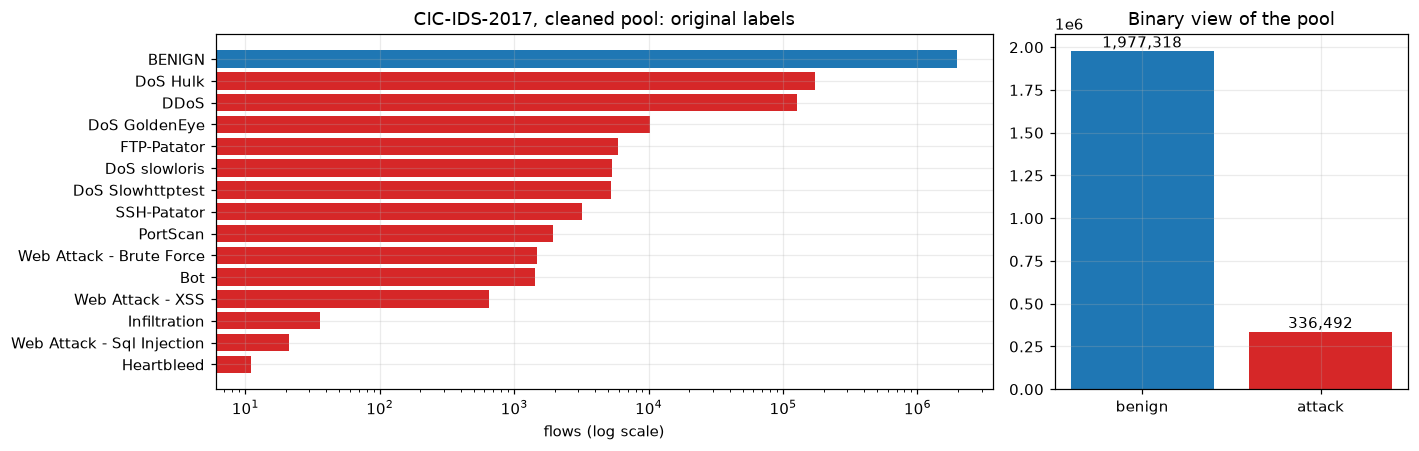

Class-balanced sample used by the model (seed 42): 10,000 flows
BENIGN                      5000
DoS Hulk                    2568
DDoS                        1921
DoS GoldenEye                149
FTP-Patator                   87
DoS Slowhttptest              81
DoS slowloris                 71
SSH-Patator                   43
Web Attack - Brute Force      27
PortScan                      26
Bot                           20
Web Attack - XSS               7


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
colors = ["tab:blue" if l == "BENIGN" else "tab:red" for l in lab_counts.index]
ax[0].barh(lab_counts.index[::-1], lab_counts.values[::-1], color=colors[::-1]); ax[0].set_xscale("log")
ax[0].set_xlabel("flows (log scale)"); ax[0].set_title("CIC-IDS-2017, cleaned pool: original labels")
bin_counts = pool["is_attack"].value_counts().sort_index()
ax[1].bar(["benign", "attack"], bin_counts.values, color=["tab:blue", "tab:red"]); ax[1].set_title("Binary view of the pool")
for i, v in enumerate(bin_counts.values): ax[1].text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

fam_all = pd.Series(np.concatenate([S0["fam_tr"], S0["fam_va"], S0["fam_te"]])).value_counts()
print(f"Class-balanced sample used by the model (seed {SEED}): {len(fam_all) and fam_all.sum():,} flows")
print(fam_all.to_string())

### The four features: ranges and shape of the distributions

Flow Duration and Flow Bytes/s span many orders of magnitude, which is why the plain min-max scaling of the paper would
push almost every flow to angles near zero. The left panels show the raw (log-axis) distributions per class, the right panels
the angles that are actually fed to the `Ry` gates after the signed `log1p` and the min-max scaling.

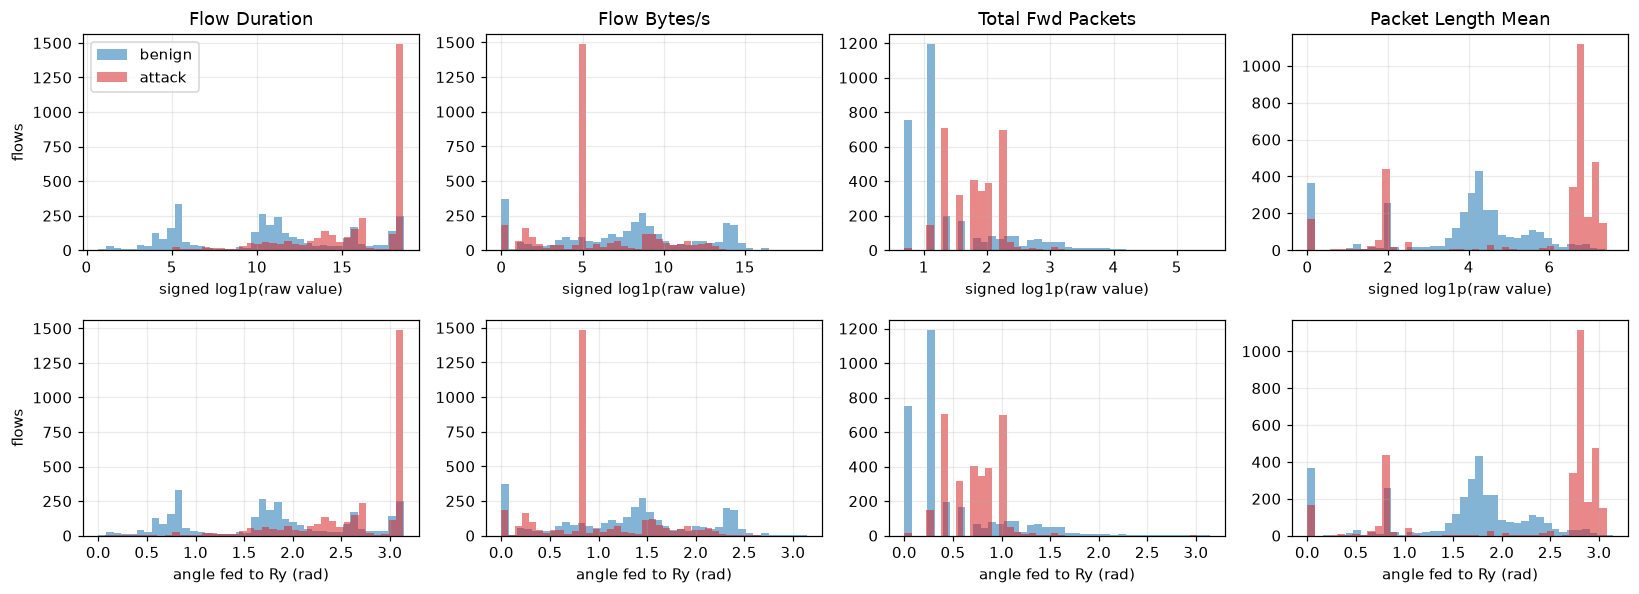

                    min           50%           max
Flow Duration       1.0  1.411542e+06  1.199994e+08
Flow Bytes/s        0.0  2.271555e+02  1.473333e+08
Total Fwd Packets   1.0  4.000000e+00  2.490000e+02
Packet Length Mean  0.0  1.043333e+02  1.937215e+03


In [9]:
Xr = S0["X_fit_raw"]; yr = S0["y_tr"]; Xa = S0["X_tr"]
fig, axes = plt.subplots(2, 4, figsize=(15, 5.5))
for j, name in enumerate(FEATURES):
    for lab, nm, c in [(0, "benign", "tab:blue"), (1, "attack", "tab:red")]:
        axes[0, j].hist(signed_log1p(Xr[yr == lab, j]), bins=40, alpha=.55, color=c, label=nm)
        axes[1, j].hist(Xa[yr == lab, j], bins=40, alpha=.55, color=c, label=nm)
    axes[0, j].set_title(name); axes[0, j].set_xlabel("signed log1p(raw value)")
    axes[1, j].set_xlabel("angle fed to Ry (rad)")
axes[0, 0].legend(); axes[0, 0].set_ylabel("flows"); axes[1, 0].set_ylabel("flows")
plt.tight_layout(); plt.show()
print(pd.DataFrame(Xr, columns=FEATURES).describe().T[["min", "50%", "max"]].to_string())

### 2-D scatter of the real training flows, coloured by ground truth

The model does not use PCA (one raw feature goes to each qubit), but a 2-D projection is the easiest way to *see* the
problem. Left: PCA (fitted on the training part) of the four angle features, coloured benign / attack. Middle: the same
points coloured by the **original attack family**. Right: the same two coordinates scaled to [0, pi], as they would be if they
were angle-encoded. Every dot is one real flow of the training split.

variance kept by the 2 PCA components: [0.542 0.338] sum 0.88


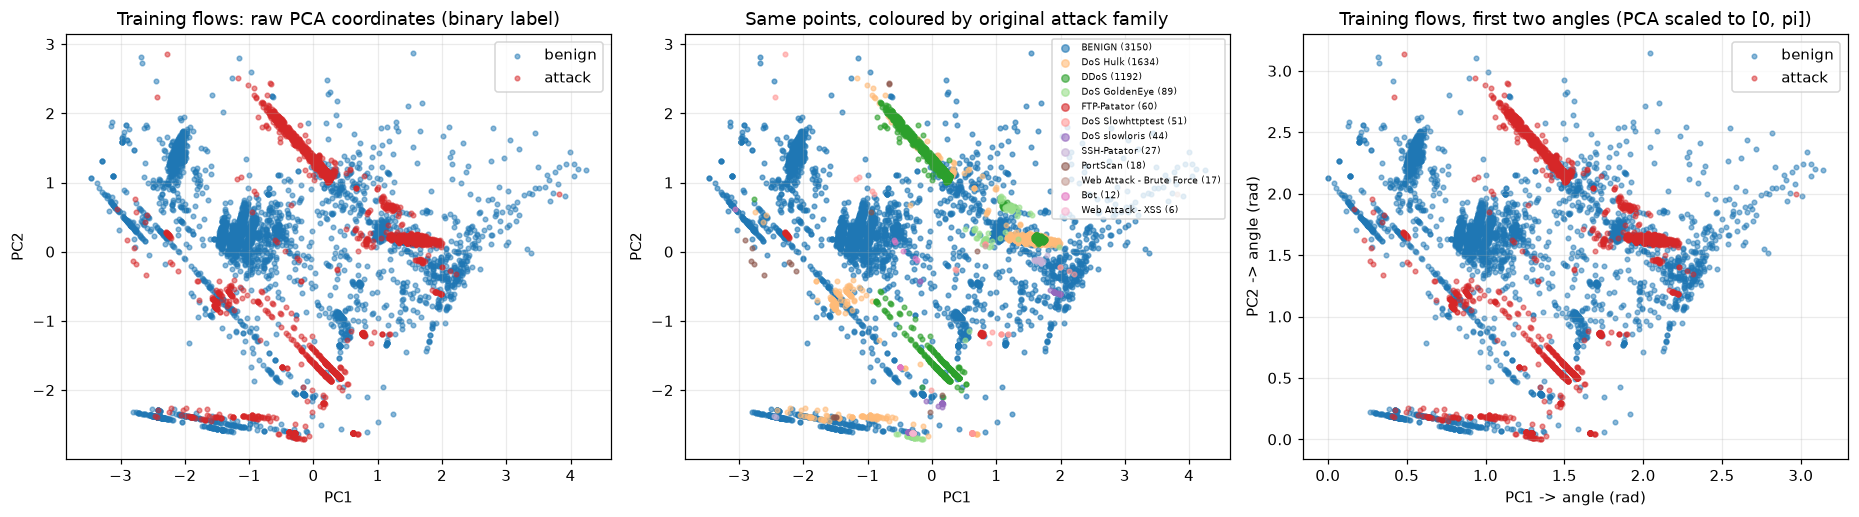

In [10]:
pca2 = make_pipeline(StandardScaler(), PCA(n_components=2, random_state=SEED)).fit(S0["X_tr"])
P_tr = pca2.transform(S0["X_tr"])
print("variance kept by the 2 PCA components:", pca2[-1].explained_variance_ratio_.round(3), "sum", pca2[-1].explained_variance_ratio_.sum().round(3))
ang2 = MinMaxScaler((0, np.pi)).fit(P_tr)
A_tr = ang2.transform(P_tr)                     # PCA coordinates scaled to [0, pi] (train-fitted)

fams = pd.Series(S0["fam_tr"]).value_counts().index.tolist()
cmap = plt.get_cmap("tab20"); fam_color = {f: ("tab:blue" if f == "BENIGN" else cmap((i + 2) % 20)) for i, f in enumerate(fams)}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for lab, nm, c in [(0, "benign", "tab:blue"), (1, "attack", "tab:red")]:
    m = S0["y_tr"] == lab; ax[0].scatter(P_tr[m, 0], P_tr[m, 1], s=9, alpha=.5, c=c, label=nm)
ax[0].set_title("Training flows: raw PCA coordinates (binary label)"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend()
for f in fams:
    m = S0["fam_tr"] == f; ax[1].scatter(P_tr[m, 0], P_tr[m, 1], s=9, alpha=.6, color=fam_color[f], label=f"{f} ({m.sum()})")
ax[1].set_title("Same points, coloured by original attack family"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
ax[1].legend(fontsize=6, markerscale=1.6, loc="best")
for lab, nm, c in [(0, "benign", "tab:blue"), (1, "attack", "tab:red")]:
    m = S0["y_tr"] == lab; ax[2].scatter(A_tr[m, 0], A_tr[m, 1], s=9, alpha=.5, c=c, label=nm)
ax[2].set_title("Training flows, first two angles (PCA scaled to [0, pi])"); ax[2].set_xlabel("PC1 -> angle (rad)"); ax[2].set_ylabel("PC2 -> angle (rad)"); ax[2].legend()
plt.tight_layout(); plt.show()

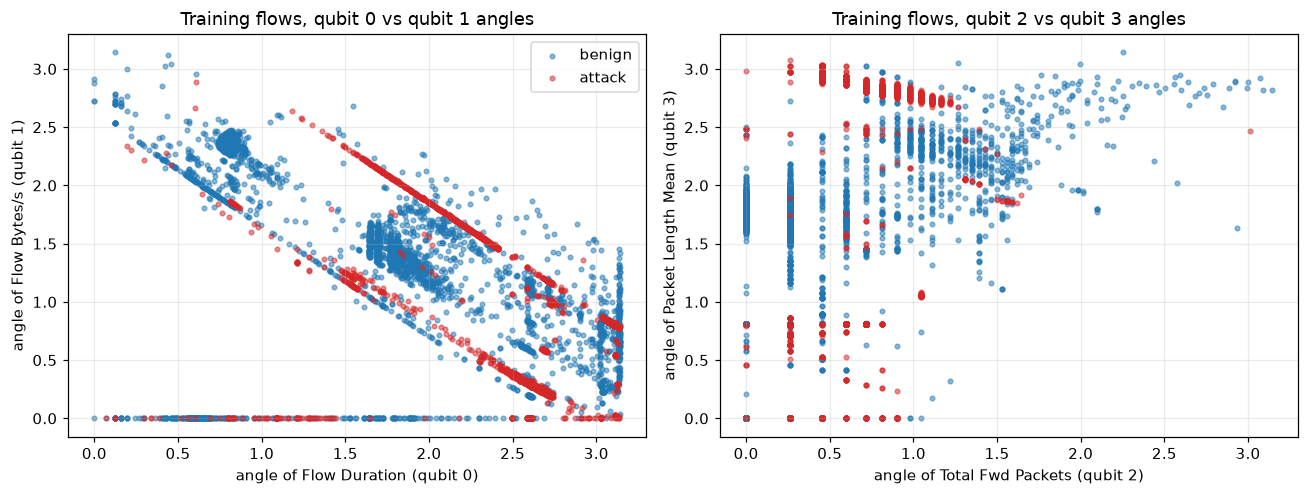

In [11]:
# The two raw features with the most visible structure, exactly as they are fed to the first two qubits.
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for lab, nm, c in [(0, "benign", "tab:blue"), (1, "attack", "tab:red")]:
    m = S0["y_tr"] == lab
    ax[0].scatter(S0["X_tr"][m, 0], S0["X_tr"][m, 1], s=9, alpha=.5, c=c, label=nm)
    ax[1].scatter(S0["X_tr"][m, 2], S0["X_tr"][m, 3], s=9, alpha=.5, c=c, label=nm)
ax[0].set_xlabel("angle of Flow Duration (qubit 0)"); ax[0].set_ylabel("angle of Flow Bytes/s (qubit 1)"); ax[0].set_title("Training flows, qubit 0 vs qubit 1 angles"); ax[0].legend()
ax[1].set_xlabel("angle of Total Fwd Packets (qubit 2)"); ax[1].set_ylabel("angle of Packet Length Mean (qubit 3)"); ax[1].set_title("Training flows, qubit 2 vs qubit 3 angles")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The paper describes the quantum processing layer in words (Fig. 1, Section IV): *angle (`Ry`) encoding, then parameterised
rotation layers and CNOT entanglement layers, 4 qubits, 3 variational layers, Pauli-Z expectation values*. It gives no gate
order, no entanglement topology and no parameter counts. The assumptions made here:

* encoding: `Ry(x_i)` on qubit *i*, once, at the start (angle embedding), features in [0, pi];
* each variational layer: a trainable `Ry(theta)` and then a trainable `Rz(phi)` on every qubit, followed by a **ring** of CNOTs
  0->1, 1->2, 2->3, 3->0 (CHOICE: the paper only says "rotation layers and entanglement layers (CNOT)");
* measurement: the Pauli-Z expectation value of every qubit, giving 4 numbers for the classical head.

The circuit below is built with Qiskit and is the **reference** for everything that follows. For training, an exact
4-qubit state-vector simulator written in PyTorch executes the same gate list (this is what makes 100 epochs on 7,000 flows
affordable on a CPU: the Qiskit primitives need one circuit evaluation per sample and per shifted parameter). The cells
below *assert* that the torch simulator and the Qiskit circuit give the same expectation values and the same
parameter-shift gradients.

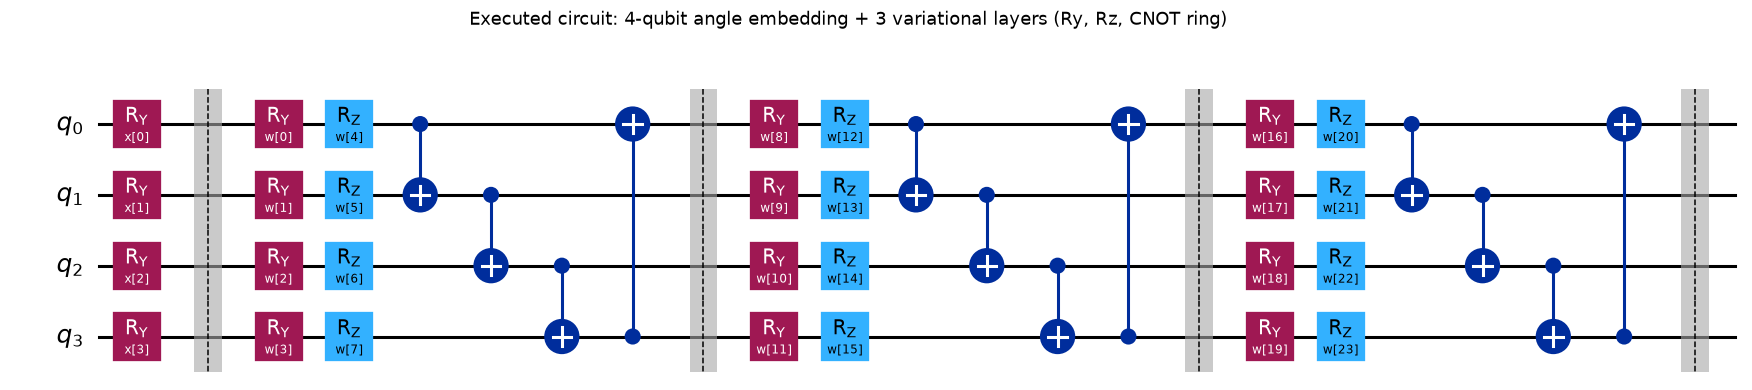

qubits          : 4
circuit depth   : 19
gate counts     : {'ry': 16, 'rz': 12, 'cx': 12, 'barrier': 4}
trainable params: 24 (3 layers x 2 rotations x 4 qubits);  data inputs: 4


In [12]:
def build_hqcvnn_circuit(n=N_QUBITS, layers=N_LAYERS):
    x = ParameterVector("x", n)                     # data (not trainable)
    w = ParameterVector("w", layers * 2 * n)        # trainable, flattened (layer, [Ry, Rz], qubit)
    qc = QuantumCircuit(n, name="HQCVNN quantum layer")
    for i in range(n):
        qc.ry(x[i], i)                              # angle embedding
    qc.barrier()
    for l in range(layers):
        for i in range(n): qc.ry(w[l * 2 * n + 0 * n + i], i)
        for i in range(n): qc.rz(w[l * 2 * n + 1 * n + i], i)
        for i in range(n): qc.cx(i, (i + 1) % n)    # ring of CNOTs
        qc.barrier()
    return qc, x, w

qc, x_params, w_params = build_hqcvnn_circuit()
Z_OBS = [SparsePauliOp("I" * (N_QUBITS - 1 - q) + "Z" + "I" * q) for q in range(N_QUBITS)]   # <Z_q>, qubit 0 = rightmost label char
fig = qc.draw("mpl", fold=-1, style="iqp")
fig.suptitle("Executed circuit: 4-qubit angle embedding + 3 variational layers (Ry, Rz, CNOT ring)", y=1.02)
display(fig)
print("qubits          :", qc.num_qubits)
print("circuit depth   :", qc.depth())
print("gate counts     :", dict(qc.count_ops()))
print("trainable params:", len(w_params), "(3 layers x 2 rotations x 4 qubits);  data inputs:", len(x_params))

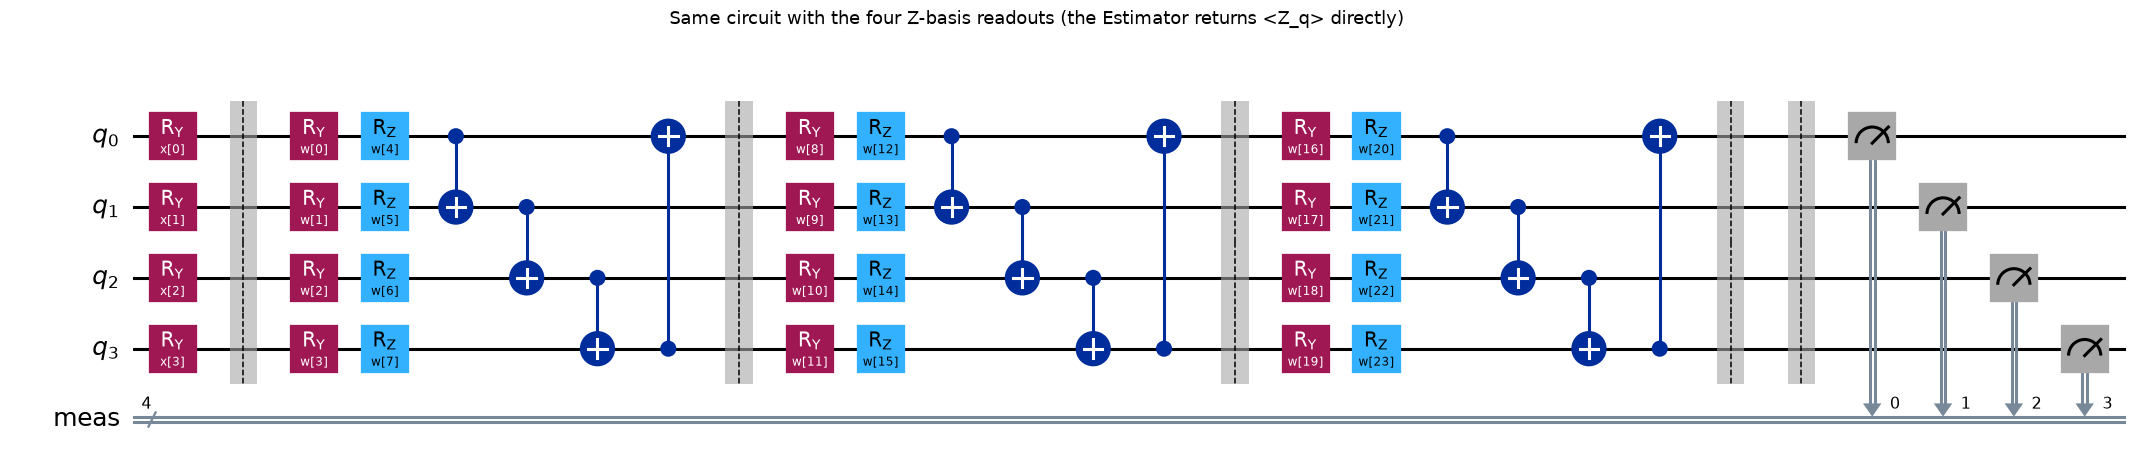

depth with measurement: 20


In [13]:
# The measurement: the Estimator evaluates <Z_q> for q = 0..3 on the final state. Drawn here with explicit readout.
qc_meas = qc.copy(); qc_meas.measure_all()
fig = qc_meas.draw("mpl", fold=-1, style="iqp")
fig.suptitle("Same circuit with the four Z-basis readouts (the Estimator returns <Z_q> directly)", y=1.02)
display(fig)
print("depth with measurement:", qc_meas.depth())

In [14]:
# ---- Exact 4-qubit state-vector simulator in PyTorch (little-endian, like Qiskit: index = q3*8 + q2*4 + q1*2 + q0) ----
def _cnot_matrix(n, c, t):
    P = np.zeros((2 ** n, 2 ** n))
    for j in range(2 ** n):
        i = j ^ (1 << t) if (j >> c) & 1 else j
        P[i, j] = 1.0
    return P

def _ring_matrix(n):
    R = np.eye(2 ** n)
    for i in range(n):                              # CNOT(0,1) first, then (1,2), ... then (n-1,0)
        R = _cnot_matrix(n, i, (i + 1) % n) @ R
    return R

def _z_signs(n):
    idx = np.arange(2 ** n)
    return np.stack([1 - 2 * ((idx >> q) & 1) for q in range(n)], axis=1).astype(float)

def _u1(theta, phi):                                # Rz(phi) @ Ry(theta)
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    ry = torch.stack([torch.stack([c, -s]), torch.stack([s, c])]).to(torch.complex128)
    rz = torch.diag(torch.stack([torch.exp(-0.5j * phi), torch.exp(0.5j * phi)]))
    return rz @ ry

class QuantumLayer(nn.Module):
    # Angle embedding + L variational layers + <Z_q> read-out, simulated exactly. Gradients by autograd
    # (identical to the parameter-shift rule for these gates; verified against Qiskit below).
    def __init__(self, n=N_QUBITS, layers=N_LAYERS, seed=0):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        # CHOICE: weights initialised uniformly in [0, 2*pi)
        self.weights = nn.Parameter(torch.rand(layers, 2, n, generator=g, dtype=torch.float64) * 2 * np.pi)
        self.n, self.layers = n, layers
        self.register_buffer("ring", torch.tensor(_ring_matrix(n), dtype=torch.complex128))
        self.register_buffer("zs", torch.tensor(_z_signs(n), dtype=torch.float64))

    def unitary(self):
        # Full 16x16 unitary of the 3 variational layers, built for all layers and qubits at once (4 qubits only).
        th, ph = self.weights[:, 0], self.weights[:, 1]                       # (layers, n)
        c, s = torch.cos(th / 2), torch.sin(th / 2)
        ry = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.complex128)   # Ry, (L, n, 2, 2)
        e = torch.stack([torch.exp(-0.5j * ph), torch.exp(0.5j * ph)], -1)                                 # diag of Rz, (L, n, 2)
        U = e[..., :, None] * ry                                              # Rz @ Ry per qubit, (L, n, 2, 2)
        assert self.n == 4, "the einsum below is written for 4 qubits"
        K = torch.einsum("lab,lcd,lef,lgh->laceg" "bdfh", U[:, 3], U[:, 2], U[:, 1], U[:, 0])  # kron, qubit 3 = most significant bit
        K = K.reshape(self.layers, 16, 16)
        V = torch.eye(16, dtype=torch.complex128)
        for l in range(self.layers):
            V = self.ring @ K[l] @ V                                          # rotations, then the CNOT ring
        return V

    def forward(self, x):                           # x: (B, n) angles
        x = x.to(torch.float64)
        v = torch.stack([torch.cos(x / 2), torch.sin(x / 2)], dim=-1)    # Ry(x)|0> per qubit, (B, n, 2)
        psi = v[:, self.n - 1]
        for q in range(self.n - 2, -1, -1):
            psi = (psi[:, :, None] * v[:, q][:, None, :]).reshape(len(x), -1)
        out = psi.to(torch.complex128) @ self.unitary().T
        return ((out.abs() ** 2) @ self.zs).to(torch.float32)           # (B, n) expectation values <Z_q>

In [15]:
# ---- Equivalence 1: expectation values, torch simulator vs Qiskit Statevector on random inputs ----
rs = np.random.default_rng(SEED)
ql = QuantumLayer(seed=SEED)
xs = rs.uniform(0, np.pi, size=(20, N_QUBITS))
w_flat = ql.weights.detach().numpy().reshape(-1)
ref = np.array([[Statevector(qc.assign_parameters(dict(zip(list(x_params) + list(w_params), np.concatenate([xv, w_flat]))))).expectation_value(o).real
                 for o in Z_OBS] for xv in xs])
mine = ql(torch.tensor(xs)).detach().numpy()
print("max |torch - qiskit| over 20 random inputs x 4 observables:", np.abs(ref - mine).max())
assert np.allclose(ref, mine, atol=1e-5), "torch simulator and Qiskit circuit disagree"

# ---- Equivalence 2: gradients. Qiskit's EstimatorQNN uses the parameter-shift rule (Eq. 10 of the paper). ----
qnn = EstimatorQNN(circuit=qc, input_params=list(x_params), weight_params=list(w_params),
                   observables=Z_OBS, input_gradients=False)
_, g_qiskit = qnn.backward(xs[:2], w_flat)                                   # (2, 4 observables, 24 weights)
xt = torch.tensor(xs[:2])

def _eval(W, xb):                                  # <Z_q> as a function of the weight tensor W (layers, 2, qubits)
    return torch.func.functional_call(ql, {"weights": W}, (xb,)).double()
g_torch = np.stack([torch.autograd.functional.jacobian(lambda W: _eval(W, xt[i:i+1])[0], ql.weights.detach()).reshape(N_QUBITS, -1).numpy()
                    for i in range(2)])
print("max |autograd - Qiskit parameter-shift| gradient difference:", np.abs(g_torch - g_qiskit).max())
assert np.allclose(g_torch, g_qiskit, atol=1e-5), "gradients disagree"

# ---- the parameter-shift rule of Eq. 10 by hand on the torch simulator, for one weight ----
k = 5; shift = np.pi / 2
Wp, Wm = ql.weights.detach().clone().reshape(-1), ql.weights.detach().clone().reshape(-1)
Wp[k] += shift; Wm[k] -= shift
fp, fm = _eval(Wp.reshape(ql.weights.shape), xt[:1]), _eval(Wm.reshape(ql.weights.shape), xt[:1])
ps = ((fp - fm) / 2).detach().numpy()[0]
print("parameter-shift (f(w+pi/2) - f(w-pi/2))/2 for weight 5:", ps.round(6), "| autograd:", g_torch[0][:, k].round(6))
print("OK: the PyTorch simulator is the Qiskit circuit above (values and parameter-shift gradients).")

max |torch - qiskit| over 20 random inputs x 4 observables: 2.703120616232013e-08


max |autograd - Qiskit parameter-shift| gradient difference: 4.440892098500626e-16
parameter-shift (f(w+pi/2) - f(w-pi/2))/2 for weight 5: [-0.039064  0.163153 -0.065342 -0.102876] | autograd: [-0.039064  0.163153 -0.065342 -0.102876]
OK: the PyTorch simulator is the Qiskit circuit above (values and parameter-shift gradients).


## 3. The hybrid model, the baselines and the training loop

* **HQCVNN** = `QuantumLayer` (24 trainable angles) -> `Linear(4, 48)` -> ReLU -> `Linear(48, 32)` -> ReLU -> `Linear(32, 2)` -> softmax
  (inside the cross-entropy loss). Total about 1,900 parameters, matching the "about 2,000" of Table I by construction.
* **ANN** = `4 -> 96 -> 72 -> 32 -> 2` with ReLU = 9,866 parameters ("about 10,000").
* **Dense head only** (extra control) = the HQCVNN's head fed with the four raw angles instead of the four `<Z>` values, i.e.
  the same network *without* the quantum layer (1,874 parameters). This is the cleanest test of the paper's claim that the
  quantum feature map is what helps.
* **SVM** = RBF kernel, `C = 1`; **Random forest** = 200 trees. Both on the identical four angle features.

All neural models use the same Adam optimiser, batch size and number of epochs.

In [16]:
class HybridNet(nn.Module):
    def __init__(self, use_quantum=True, seed=0):
        super().__init__()
        torch.manual_seed(seed)
        self.q = QuantumLayer(seed=seed) if use_quantum else None
        self.head = nn.Sequential(nn.Linear(N_QUBITS, 48), nn.ReLU(), nn.Linear(48, 32), nn.ReLU(), nn.Linear(32, 2))
    def forward(self, x):
        return self.head(self.q(x) if self.q is not None else x)

class ANN(nn.Module):
    def __init__(self, seed=0):
        super().__init__()
        torch.manual_seed(seed)
        self.net = nn.Sequential(nn.Linear(4, 96), nn.ReLU(), nn.Linear(96, 72), nn.ReLU(), nn.Linear(72, 32), nn.ReLU(), nn.Linear(32, 2))
    def forward(self, x): return self.net(x)

n_params = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
print("HQCVNN trainable parameters   :", n_params(HybridNet(True)), "(24 quantum +", n_params(HybridNet(True)) - 24, "classical)   paper: ~2,000")
print("Dense head only (no quantum)  :", n_params(HybridNet(False)))
print("ANN baseline                  :", n_params(ANN()), "  paper: ~10,000")

def train_torch(model, S, epochs=None, lr=None, seed=0, log_every=None):
    epochs, lr = epochs or EPOCHS, lr or LR
    Xtr, ytr = torch.tensor(S["X_tr"], dtype=torch.float32), torch.tensor(S["y_tr"])
    Xva, yva = torch.tensor(S["X_va"], dtype=torch.float32), torch.tensor(S["y_va"])
    opt, lossf = torch.optim.Adam(model.parameters(), lr=lr), nn.CrossEntropyLoss()
    g = torch.Generator().manual_seed(seed); hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr), generator=g); run = 0.0
        for i in range(0, len(Xtr), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            opt.zero_grad(); loss = lossf(model(Xtr[b]), ytr[b]); loss.backward(); opt.step()
            run += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            vo = model(Xva); hist["val_loss"].append(lossf(vo, yva).item()); hist["val_acc"].append((vo.argmax(1) == yva).float().mean().item())
        hist["train_loss"].append(run / len(Xtr))
        if log_every and (ep + 1) % log_every == 0:
            print(f"  epoch {ep+1:3d}/{epochs}  train loss {hist['train_loss'][-1]:.4f}  val loss {hist['val_loss'][-1]:.4f}  val acc {hist['val_acc'][-1]:.3f}")
    return hist, time.time() - t0

def predict_torch(model, X):
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(torch.tensor(X, dtype=torch.float32)), 1)[:, 1].numpy()
    return p

def metrics(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return dict(accuracy=100 * accuracy_score(y, yhat), precision=precision_score(y, yhat, zero_division=0),
                recall=recall_score(y, yhat), f1=f1_score(y, yhat), auc=roc_auc_score(y, p))

HQCVNN trainable parameters   : 1898 (24 quantum + 1874 classical)   paper: ~2,000
Dense head only (no quantum)  : 1874
ANN baseline                  : 9866   paper: ~10,000


### 3.1 Training the HQCVNN once (seed 42) and watching the loss (the paper's Fig. 5)

  epoch  10/100  train loss 0.1422  val loss 0.1503  val acc 0.946


  epoch  20/100  train loss 0.1261  val loss 0.1704  val acc 0.946


  epoch  30/100  train loss 0.1219  val loss 0.1520  val acc 0.950


  epoch  40/100  train loss 0.1178  val loss 0.1369  val acc 0.953


  epoch  50/100  train loss 0.1189  val loss 0.1409  val acc 0.947


  epoch  60/100  train loss 0.1144  val loss 0.1371  val acc 0.949


  epoch  70/100  train loss 0.1136  val loss 0.1443  val acc 0.949


  epoch  80/100  train loss 0.1063  val loss 0.1256  val acc 0.951


  epoch  90/100  train loss 0.1081  val loss 0.1387  val acc 0.941


  epoch 100/100  train loss 0.1084  val loss 0.1276  val acc 0.957
trained in 240 s


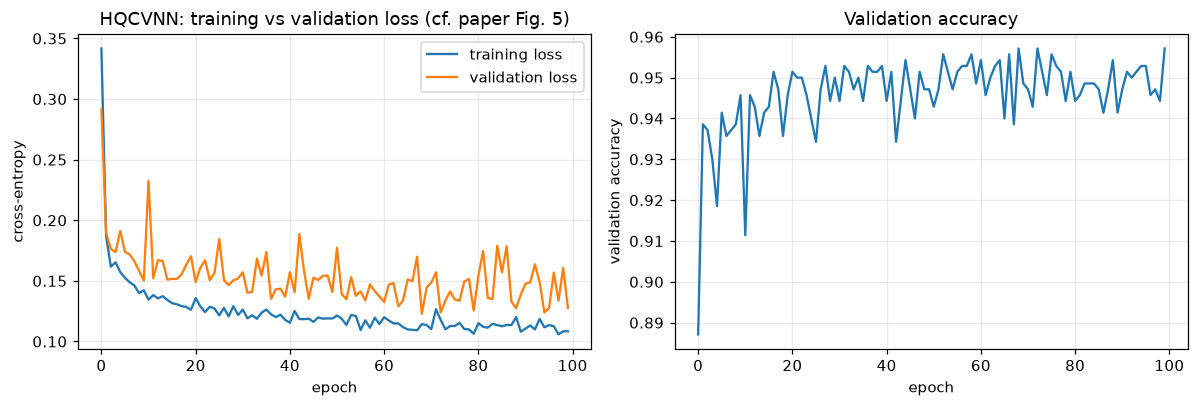

In [17]:
model_q = HybridNet(True, seed=SEED)
hist_q, t_q = train_torch(model_q, S0, seed=SEED, log_every=max(1, EPOCHS // 10))
print(f"trained in {t_q:.0f} s")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(hist_q["train_loss"], label="training loss"); ax[0].plot(hist_q["val_loss"], label="validation loss")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy"); ax[0].set_title("HQCVNN: training vs validation loss (cf. paper Fig. 5)"); ax[0].legend()
ax[1].plot(hist_q["val_acc"]); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy"); ax[1].set_title("Validation accuracy")
plt.tight_layout(); plt.show()

In [18]:
# Re-run the trained model through the real Qiskit circuit (EstimatorQNN + TorchConnector) on test flows:
# the quantum-layer outputs and the final predictions must be identical to the fast simulator's.
trained_w = model_q.q.weights.detach().numpy().reshape(-1)
Xchk = S0["X_te"][:60]
qk_out = qnn.forward(Xchk, trained_w)                                    # Qiskit Statevector Estimator, 60 flows
sim_out = model_q.q(torch.tensor(Xchk)).detach().numpy()
print("max |Qiskit - simulator| quantum-layer output on 60 test flows:", np.abs(qk_out - sim_out).max())
with torch.no_grad():
    p_qiskit = torch.softmax(model_q.head(torch.tensor(qk_out, dtype=torch.float32)), 1)[:, 1].numpy()
p_sim = predict_torch(model_q, Xchk)
print("predictions identical through Qiskit and the simulator:", bool(((p_qiskit >= .5) == (p_sim >= .5)).all()))
assert np.allclose(qk_out, sim_out, atol=1e-5)

max |Qiskit - simulator| quantum-layer output on 60 test flows: 1.4231150813337479e-08
predictions identical through Qiskit and the simulator: True


## 4. All models, several seeds

For every seed the whole pipeline is repeated: a new balanced sample, a new split, new initial weights and a new shuffling
order. The SVM and the random forest use the same split and inputs.

In [19]:
def run_all_models(S, seed, tag=""):
    rows, extra = [], {}
    # --- SVM (rbf) ---
    t0 = time.time(); svm = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed).fit(S["X_tr"], S["y_tr"])
    s_svm = svm.decision_function(S["X_te"]); t_svm = time.time() - t0
    yhat = (s_svm > 0).astype(int)
    rows.append(dict(seed=seed, model="SVM (rbf)", accuracy=100 * accuracy_score(S["y_te"], yhat), precision=precision_score(S["y_te"], yhat, zero_division=0),
                     recall=recall_score(S["y_te"], yhat), f1=f1_score(S["y_te"], yhat), auc=roc_auc_score(S["y_te"], s_svm), params=np.nan, time_s=t_svm))
    extra["SVM (rbf)"] = (s_svm - s_svm.min()) / (s_svm.max() - s_svm.min())
    # --- random forest ---
    t0 = time.time(); rf = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=2).fit(S["X_tr"], S["y_tr"])
    p_rf = rf.predict_proba(S["X_te"])[:, 1]; t_rf = time.time() - t0
    rows.append(dict(seed=seed, model="Random forest", **metrics(S["y_te"], p_rf), params=np.nan, time_s=t_rf)); extra["Random forest"] = p_rf
    # --- neural models ---
    for name, mk in [("ANN", lambda: ANN(seed)), ("Dense head only (no quantum)", lambda: HybridNet(False, seed)), ("HQCVNN", lambda: HybridNet(True, seed))]:
        m = mk()
        if name == "HQCVNN" and seed == SEED and S is S0:      # reuse the model trained in 3.1
            m, h, t = model_q, hist_q, t_q
        else:
            h, t = train_torch(m, S, seed=seed)
        p = predict_torch(m, S["X_te"])
        rows.append(dict(seed=seed, model=name, **metrics(S["y_te"], p), params=n_params(m), time_s=t)); extra[name] = p
        extra[name + "_hist"] = h; extra[name + "_model"] = m
    print(f"{tag}seed {seed}: " + ", ".join(f"{r['model']} {r['accuracy']:.1f}%" for r in rows))
    return rows, extra

all_rows, EXTRA = [], {}
for k in range(N_SEEDS):
    sd = SEED + k
    S = S0 if sd == SEED else make_split(sd)
    r, e = run_all_models(S, sd); all_rows += r
    if sd == SEED: EXTRA = e
res = pd.DataFrame(all_rows)

seed 42: SVM (rbf) 94.9%, Random forest 98.1%, ANN 96.1%, Dense head only (no quantum) 96.3%, HQCVNN 96.3%


seed 43: SVM (rbf) 93.3%, Random forest 97.4%, ANN 95.8%, Dense head only (no quantum) 96.3%, HQCVNN 96.3%


seed 44: SVM (rbf) 93.4%, Random forest 97.7%, ANN 96.1%, Dense head only (no quantum) 96.2%, HQCVNN 96.1%


In [20]:
order = ["SVM (rbf)", "Random forest", "ANN", "Dense head only (no quantum)", "HQCVNN"]
agg = res.groupby("model").agg(["mean", "std"]).reindex(order)
summary = pd.DataFrame({
    "Accuracy %": [f"{agg.loc[m, ('accuracy','mean')]:.2f} ± {np.nan_to_num(agg.loc[m, ('accuracy','std')]):.2f}" for m in order],
    "Precision": [f"{agg.loc[m, ('precision','mean')]:.3f}" for m in order],
    "Recall": [f"{agg.loc[m, ('recall','mean')]:.3f}" for m in order],
    "F1": [f"{agg.loc[m, ('f1','mean')]:.3f}" for m in order],
    "AUC": [f"{agg.loc[m, ('auc','mean')]:.3f}" for m in order],
    "Params": [("-" if np.isnan(agg.loc[m, ('params','mean')]) else f"{int(agg.loc[m, ('params','mean')]):,}") for m in order],
    "Train time (s)": [f"{agg.loc[m, ('time_s','mean')]:.1f}" for m in order]}, index=order)
print(f"Test-set results, mean ± std over {N_SEEDS} seed(s), attack = positive class:")
print(summary.to_string())

Test-set results, mean ± std over 3 seed(s), attack = positive class:
                                Accuracy % Precision Recall     F1    AUC Params Train time (s)
SVM (rbf)                     93.88 ± 0.92     0.946  0.931  0.938  0.974      -            3.0
Random forest                 97.73 ± 0.35     0.976  0.979  0.977  0.996      -            4.0
ANN                           96.01 ± 0.16     0.965  0.955  0.960  0.991  9,866          183.0
Dense head only (no quantum)  96.27 ± 0.09     0.967  0.958  0.962  0.991  1,874          132.0
HQCVNN                        96.23 ± 0.15     0.969  0.955  0.962  0.990  1,898          352.5


## 5. Re-drawing the paper's figures and tables (seed 42)

Table II (confusion matrix), Fig. 3 (accuracy bars), Fig. 4 (ROC curves) and Fig. 5 (loss curves, already drawn in 3.1).

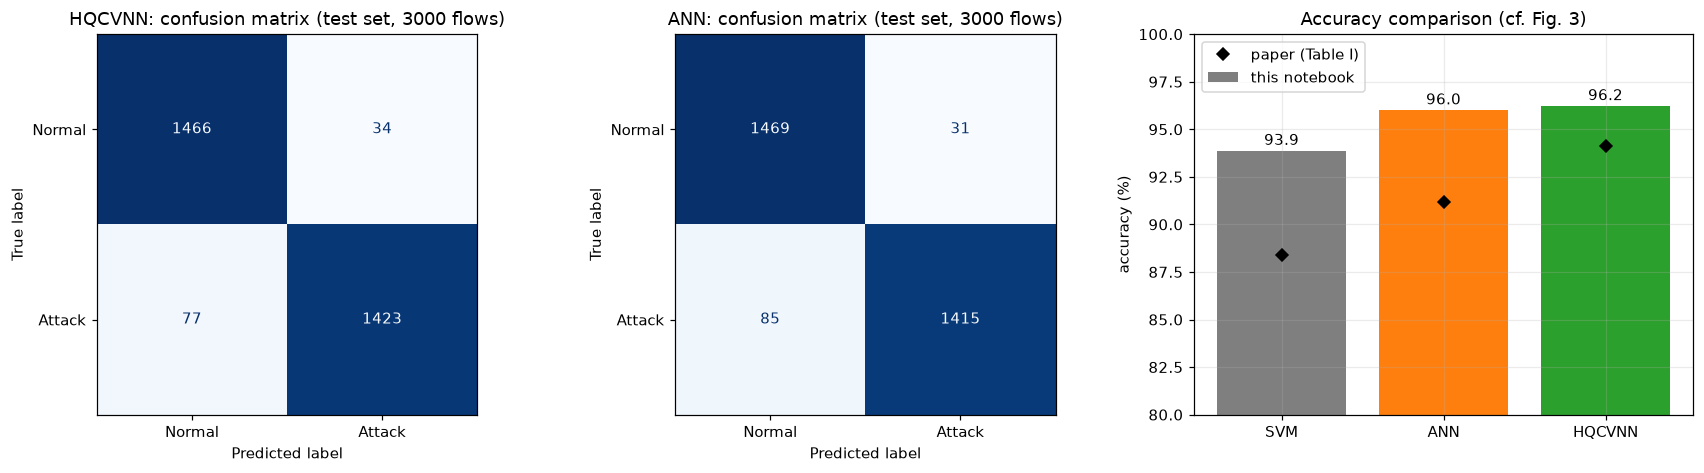

HQCVNN: TN=1466 FP=34 FN=77 TP=1423  (paper Table II on 3,000 flows: TN 1450, FP 70, FN 85, TP 1395)
rates : FP rate 0.023 (paper 70/1520 = 0.046), FN rate 0.051 (paper 85/1480 = 0.057)


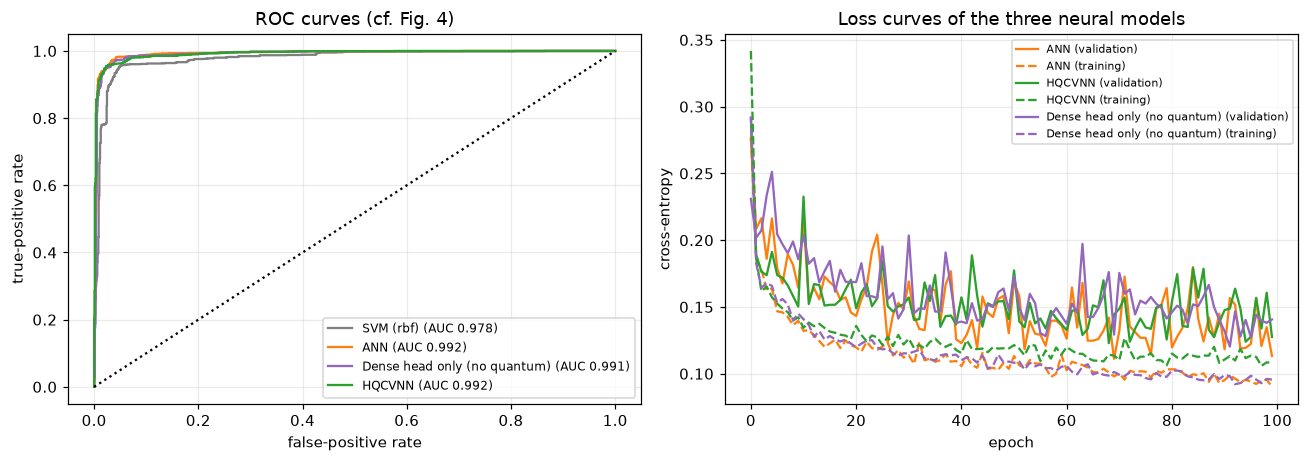

In [21]:
yte = S0["y_te"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for a, name in zip(ax[:2], ["HQCVNN", "ANN"]):
    cm = confusion_matrix(yte, (EXTRA[name] >= .5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Normal", "Attack"]).plot(ax=a, colorbar=False, cmap="Blues", values_format="d")
    a.grid(False); a.set_title(f"{name}: confusion matrix (test set, {len(yte)} flows)")
accs = [agg.loc[m, ("accuracy", "mean")] for m in ["SVM (rbf)", "ANN", "HQCVNN"]]
bars = ax[2].bar(["SVM", "ANN", "HQCVNN"], accs, color=["tab:gray", "tab:orange", "tab:green"], label="this notebook")
ax[2].plot(["SVM", "ANN", "HQCVNN"], [88.4, 91.2, 94.1], "kD", label="paper (Table I)")
for b, v in zip(bars, accs): ax[2].text(b.get_x() + b.get_width() / 2, v + .3, f"{v:.1f}", ha="center")
ax[2].set_ylim(min(80, min(accs) - 3), 100); ax[2].set_ylabel("accuracy (%)"); ax[2].set_title("Accuracy comparison (cf. Fig. 3)"); ax[2].legend()
plt.tight_layout(); plt.show()
cmq = confusion_matrix(yte, (EXTRA["HQCVNN"] >= .5).astype(int)); tn, fp, fn, tp = cmq.ravel()
print(f"HQCVNN: TN={tn} FP={fp} FN={fn} TP={tp}  (paper Table II on 3,000 flows: TN 1450, FP 70, FN 85, TP 1395)")
print(f"rates : FP rate {fp/(fp+tn):.3f} (paper 70/1520 = 0.046), FN rate {fn/(fn+tp):.3f} (paper 85/1480 = 0.057)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for name, c in [("SVM (rbf)", "tab:gray"), ("ANN", "tab:orange"), ("Dense head only (no quantum)", "tab:purple"), ("HQCVNN", "tab:green")]:
    fpr, tpr, _ = roc_curve(yte, EXTRA[name]); ax[0].plot(fpr, tpr, color=c, label=f"{name} (AUC {roc_auc_score(yte, EXTRA[name]):.3f})")
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_xlabel("false-positive rate"); ax[0].set_ylabel("true-positive rate"); ax[0].set_title("ROC curves (cf. Fig. 4)"); ax[0].legend(fontsize=8)
for name, c in [("ANN", "tab:orange"), ("HQCVNN", "tab:green"), ("Dense head only (no quantum)", "tab:purple")]:
    h = EXTRA[name + "_hist"]; ax[1].plot(h["val_loss"], color=c, label=name + " (validation)"); ax[1].plot(h["train_loss"], color=c, ls="--", label=name + " (training)")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("cross-entropy"); ax[1].set_title("Loss curves of the three neural models"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 6. Ablation: the paper's literal preprocessing (plain min-max, no log)

The paper says "min-max normalisation" and nothing else. On these four heavy-tailed features that squeezes nearly all flows
towards angle 0. The cell below repeats the experiment (seed 42) with the literal preprocessing for the SVM, ANN and HQCVNN
so the effect of the log transform used above is visible.

In [22]:
S_lit = make_split(SEED, log_transform=False)
rows_lit = []
svm_l = SVC(kernel="rbf", C=1.0, gamma="scale").fit(S_lit["X_tr"], S_lit["y_tr"]); sc = svm_l.decision_function(S_lit["X_te"])
rows_lit.append(dict(model="SVM (rbf)", accuracy=100 * accuracy_score(S_lit["y_te"], sc > 0), auc=roc_auc_score(S_lit["y_te"], sc)))
for name, m in [("ANN", ANN(SEED)), ("HQCVNN", HybridNet(True, SEED))]:
    train_torch(m, S_lit, seed=SEED); p = predict_torch(m, S_lit["X_te"]); mm = metrics(S_lit["y_te"], p)
    rows_lit.append(dict(model=name, accuracy=mm["accuracy"], auc=mm["auc"]))
lit = pd.DataFrame(rows_lit).set_index("model")
lit["accuracy (log1p + min-max, main run)"] = [res[(res.model == m) & (res.seed == SEED)].accuracy.iloc[0] for m in lit.index]
print("Literal min-max preprocessing (seed 42) vs the signed-log1p + min-max used in the main run:")
print(lit.round(3).to_string())

Literal min-max preprocessing (seed 42) vs the signed-log1p + min-max used in the main run:
           accuracy    auc  accuracy (log1p + min-max, main run)
model                                                           
SVM (rbf)    88.733  0.966                                94.933
ANN          95.833  0.990                                96.133
HQCVNN       89.767  0.971                                96.300


## 7. Side-by-side comparison with the paper

Tolerance used for a verdict: **reproduced** if the notebook's mean is within 2 accuracy points (0.02 for precision, recall,
F1 and AUC) of the paper's number; otherwise **not reached** (notebook lower) or **exceeded** (notebook higher), with the gap.

In [23]:
def M(model, key): return agg.loc[model, (key, "mean")]
def verdict(nb, paper, tol):
    d = nb - paper
    return "reproduced" if abs(d) <= tol else (f"not reached ({d:+.3g})" if d < 0 else f"exceeded ({d:+.3g})")

claims = []
paper_table1 = {"SVM (rbf)": (88.4, .86, .85, .85, .89), "ANN": (91.2, .89, .90, .89, .92), "HQCVNN": (94.1, .93, .92, .92, .96)}
for model, vals in paper_table1.items():
    for key, pv, tol in zip(["accuracy", "precision", "recall", "f1", "auc"], vals, [2, .02, .02, .02, .02]):
        claims.append((f"Table I {model.split(' ')[0]} {key}", pv, M(model, key), verdict(M(model, key), pv, tol)))
# Table II (implied rates and metrics)
claims.append(("Table II FP rate (70/1520)", 70 / 1520, fp / (fp + tn), verdict(fp / (fp + tn), 70 / 1520, .02)))
claims.append(("Table II FN rate (85/1480)", 85 / 1480, fn / (fn + tp), verdict(fn / (fn + tp), 85 / 1480, .02)))
claims.append(("Table II implied accuracy % (2845/3000)", 100 * 2845 / 3000, M("HQCVNN", "accuracy"), verdict(M("HQCVNN", "accuracy"), 100 * 2845 / 3000, 2)))
acc_order = M("HQCVNN", "accuracy") > M("ANN", "accuracy") > M("SVM (rbf)", "accuracy")
auc_order = M("HQCVNN", "auc") > M("ANN", "auc") > M("SVM (rbf)", "auc")
claims.append(("Fig. 3: accuracy HQCVNN > ANN > SVM", "True", str(bool(acc_order)), "reproduced" if acc_order else "not reached"))
claims.append(("Fig. 4 / Table III: AUC HQCVNN > ANN > SVM", "True", str(bool(auc_order)), "reproduced" if auc_order else "not reached"))
claims.append(("Parameters HQCVNN (about 2,000)", 2000, M("HQCVNN", "params"), "cannot be checked (paper gives no architecture; head sized by us)"))
claims.append(("Parameters ANN (about 10,000)", 10000, M("ANN", "params"), "cannot be checked (paper gives no architecture; sized by us)"))
slower = M("HQCVNN", "time_s") > M("ANN", "time_s")
claims.append(("Conclusion: training slightly slower than classical", "True", f"{M('HQCVNN','time_s'):.0f}s vs {M('ANN','time_s'):.0f}s", "reproduced" if slower else "not reached"))
hv, tv = EXTRA["HQCVNN_hist"], EXTRA["HQCVNN_hist"]
gap = hv["val_loss"][-1] - hv["train_loss"][-1]
claims.append(("Fig. 5: train/val loss fall together (final gap)", "small", f"{gap:+.3f}", "reproduced" if abs(gap) < .05 and hv["val_loss"][-1] < hv["val_loss"][0] else "not reached"))
q_gain = M("HQCVNN", "accuracy") - M("Dense head only (no quantum)", "accuracy")
sd = res[res.model == "HQCVNN"].accuracy.std() if N_SEEDS > 1 else np.nan
claims.append(("Conclusion: the quantum feature map improves separability (HQCVNN minus same head without quantum layer, accuracy points)",
               "> 0", f"{q_gain:+.2f}", "supported" if q_gain > 1.0 else "not supported (gain within 1 point)"))
cmp_df = pd.DataFrame(claims, columns=["Claim", "Paper", "This notebook", "Verdict"])
cmp_df["Paper"] = cmp_df["Paper"].map(lambda v: f"{v:.3f}" if isinstance(v, float) else str(v))
cmp_df["This notebook"] = cmp_df["This notebook"].map(lambda v: f"{v:.3f}" if isinstance(v, (float, np.floating)) else str(v))
pd.set_option("display.width", 220, "display.max_colwidth", 110)
print(cmp_df.to_string(index=False))
n_rep = cmp_df.Verdict.str.startswith("reproduced").sum()
print(f"\n{n_rep} of {len(cmp_df)} claims reproduced within tolerance; "
      f"{cmp_df.Verdict.str.startswith('not').sum()} not reached, {cmp_df.Verdict.str.startswith('exceeded').sum()} exceeded, "
      f"{cmp_df.Verdict.str.startswith('cannot').sum()} cannot be checked.")

                                                                                                                    Claim  Paper This notebook                                                           Verdict
                                                                                                     Table I SVM accuracy 88.400        93.878                                                  exceeded (+5.48)
                                                                                                    Table I SVM precision  0.860         0.946                                                exceeded (+0.0861)
                                                                                                       Table I SVM recall  0.850         0.931                                                exceeded (+0.0807)
                                                                                                           Table I SVM f1  0.850         0.938                      

## 8. Reading the paper critically

* **Table I and Table II do not agree with each other.** The confusion matrix of Table II (TN 1450, FP 70, FN 85, TP 1395) gives
  accuracy 94.8 %, precision 0.952, recall 0.943 and F1 0.947, not the 94.1 % / 0.93 / 0.92 / 0.92 of Table I. The conclusion also
  quotes Table I. At least one of the two tables was not produced from the run it describes.
* **"IoT" intrusion detection on a non-IoT dataset.** Title, abstract and conclusion speak of IoT, but the only data are the
  CIC-IDS-2017 lab-network flows (PCs, servers, one firewall), where the attacks are DoS, DDoS, port scans and web attacks.
  Nothing in the experiment tests IoT devices or IoT protocols.
* **Four features make the classification easy and the comparison thin.** The four features were chosen by hand ("importance
  ranking and correlation analysis" is mentioned but no ranking is shown). With these inputs every reasonable classical model
  is already close to the reported numbers, and a random forest on the same four inputs is a stronger classical baseline than
  the SVM and the ANN of the paper. The paper compares only against an untuned SVM and an ANN whose architecture is not given.
* **"About 2,000 parameters" cannot come from the quantum part.** The 4-qubit, 3-layer circuit has 24 trainable angles
  (or 36 with a third rotation per qubit). Everything else is the dense head, whose size is a free choice. The parameter
  advantage over the ANN is therefore a statement about the dense layers, not about quantum circuits.
* **The control that matters is missing.** Whether the variational circuit contributes anything is answered by training the
  same dense head on the same inputs *without* the quantum layer. That ablation is in section 7 above; without it "quantum-enhanced
  feature mapping improves separability" is not a tested claim. Four `Ry`-encoded qubits with a CNOT ring also produce only smooth
  trigonometric functions of the four angles, which a 2-layer dense head can approximate itself.
* **Simulation only.** The paper says the model is "suitable for NISQ-era computers" but reports no noise model, no shot noise
  and no hardware run; all numbers come from ideal simulation. The parameter-shift rule is stated, but the exact simulator
  makes autograd equivalent, so nothing about NISQ training cost is measured.
* **Missing details and one slip.** No learning rate, seed, number of runs, sample size or standard deviation is given; the
  text refers to "Figure X" and to a "VQ-VAE1 model" that does not appear anywhere else, which suggests text re-used from another
  paper. The related-work and background parts cite graph-neural-network IDS papers for statements about quantum computing.
* **The single-number comparison hides class structure.** Binary attack/normal accuracy on a pool dominated by DoS Hulk
  and DDoS says nothing about rare families (infiltration, SQL injection, Heartbleed). Section "Dataset Exploration and Visualisation"
  shows how few flows those families have.

## 9. Exercises

1. **Which classical features matter?** Replace the four features by the top four from `SelectKBest(f_classif)` on all CICFlowMeter
   columns (fitted on the training part). Do the SVM, ANN and HQCVNN keep their ordering?
2. **Entanglement or not?** Remove the CNOT ring (set `ring` to the identity in `QuantumLayer`) and retrain. Does accuracy drop?
   What does that say about the paper's claim that entanglement "improves nonlinear feature interaction"?
3. **Depth sweep.** Run `N_LAYERS = 1, 2, 3, 5` and plot test accuracy against the number of trainable quantum parameters.
   Compare with a dense head that has the same number of extra parameters.
4. **Noise and shots.** Replace the exact expectation values by estimates from 1,024 shots (add Gaussian noise of standard
   deviation `1/sqrt(1024)` to the `<Z>` values, or use `qiskit_aer` with a fake backend noise model) and measure the accuracy loss.
5. **Rare attacks.** Evaluate the trained HQCVNN per original attack family (`fam_te` in `make_split`) and report recall for
   Bot, Web Attack and Infiltration. Which families does the paper's binary accuracy hide?